In [1]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [4]:
import torch
import random
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [7]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [8]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/duduyemiolamilekan
/kaggle/input/datasets/duduyemiolamilekan/breakhis
/kaggle/input/datasets/forderation
/kaggle/input/datasets/forderation/breakhis-400x
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/test
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/test/benign
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/test/malignant
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/train
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/train/benign
/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/train/malignant
/kaggle/input/models
/kaggle/input/models/duduyemiolamilekan
/kaggle/input/models/duduyemiolamilekan/baseline-resnet-50-breast-cancer-classifier
/kaggle/input/models/duduyemiolamilekan/baseline-resnet-50-breast-cancer-classifier/pytorch
/kaggle/input/models/duduyemiolamilekan/b

In [9]:
DATA_PATH = "/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X"
MODEL_PATH = "/kaggle/input/models/duduyemiolamilekan/baseline-resnet-50-breast-cancer-classifier/pytorch/default/1"
import os

print(os.listdir(DATA_PATH))

['test', 'train']


In [11]:
DATASET_PATH = "/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X"

TRAIN_DIR = f"{DATASET_PATH}/train"
TEST_DIR  = f"{DATASET_PATH}/test"

import os
import torch

DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Kaggle dataset path
DATA_DIR    = "/kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X"

# Kaggle writable directory
MODEL_DIR   = "/kaggle/working/breast_cancer_models"

IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS_BASE = 30
EPOCHS_ADV  = 20

LR          = 1e-4
LR_ADV      = 5e-5
WEIGHT_DECAY= 1e-5

EPS         = 8/255
ALPHA       = EPS / 4
PGD_STEPS   = 15

os.makedirs(MODEL_DIR, exist_ok=True)

print(f"Using device: {DEVICE}")

Using device: cuda


In [12]:
from PIL import Image
from tqdm import tqdm
import os

bad_files = []
all_images = []

for root, dirs, files in os.walk(DATA_DIR):

    for file in files:

        if file.lower().endswith(('.png', '.jpg', '.jpeg')):

            all_images.append(os.path.join(root, file))

print("Total images:", len(all_images))

for path in tqdm(all_images):

    try:
        img = Image.open(path)
        img.verify()

    except Exception:
        bad_files.append(path)

print("\nCorrupted images found:", len(bad_files))

for path in bad_files:
    print(path)

Total images: 1693


100%|██████████| 1693/1693 [00:12<00:00, 133.60it/s]


Corrupted images found: 0


In [13]:
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import numpy as np
import torch
import os

# =========================
# Paths
# =========================

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR  = os.path.join(DATA_DIR, "test")

# =========================
# Transforms
# =========================

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# =========================
# Datasets
# =========================

train_dataset = ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

test_dataset = ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)

print("Classes:", train_dataset.classes)
print("Train images:", len(train_dataset))
print("Test images:", len(test_dataset))

# =========================
# DataLoaders
# =========================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

# =========================
# Class Weights
# =========================

labels = train_dataset.targets
class_counts = np.bincount(labels)

n_benign    = class_counts[0]
n_malignant = class_counts[1]
n_total     = len(labels)

weight_benign    = n_total / (2 * n_benign)
weight_malignant = n_total / (2 * n_malignant)

class_weights = torch.tensor(
    [weight_benign, weight_malignant],
    dtype=torch.float
).to(DEVICE)

print("Class weights:", class_weights)

print("Done ✅")

Classes: ['benign', 'malignant']
Train images: 1148
Test images: 545
Class weights: tensor([1.5472, 0.7387], device='cuda:0')
Done ✅


In [14]:
from torch.utils.data import random_split, DataLoader

# Split training set into train + validation
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)

# DataLoaders
train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train subset:", len(train_subset))
print("Validation subset:", len(val_subset))

Train subset: 976
Validation subset: 172


In [15]:
from torchvision.datasets import ImageFolder

full_dataset = ImageFolder(
    root=DATA_DIR,
    transform=test_transform
)

print(full_dataset.classes)
print(len(full_dataset))

['test', 'train']
1693


Image path: /kaggle/input/datasets/forderation/breakhis-400x/BreaKHis 400X/test/benign/SOB_B_A-14-22549AB-400-001.png
Image size: (700, 460)
Image mode: RGB


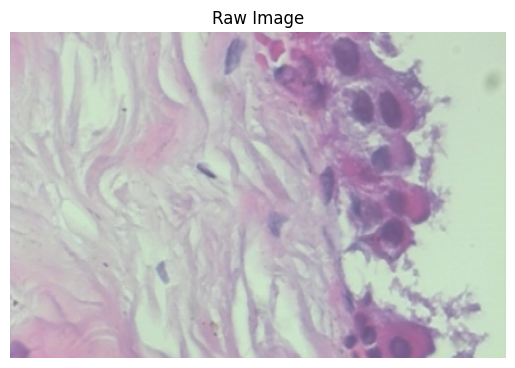

In [14]:
# DEBUG CELL — run this first

test_img_path = full_dataset.samples[0][0]

test_img = Image.open(test_img_path).convert("RGB")

print("Image path:", test_img_path)
print("Image size:", test_img.size)
print("Image mode:", test_img.mode)

plt.imshow(np.array(test_img))
plt.title("Raw Image")
plt.axis('off')
plt.show()

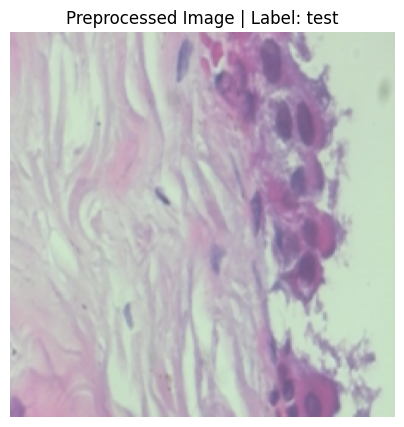

In [15]:
# Get one preprocessed image
img_tensor, label = full_dataset[0]

# Convert tensor to numpy
img = img_tensor.permute(1, 2, 0).numpy()

# Undo normalization
img = img * np.array(STD) + np.array(MEAN)

# Keep values between 0 and 1
img = np.clip(img, 0, 1)

# Display
plt.figure(figsize=(5,5))
plt.imshow(img)
plt.title(f"Preprocessed Image | Label: {full_dataset.classes[label]}")
plt.axis('off')
plt.show()

In [17]:
def build_resnet50(freeze_early=True):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    if freeze_early:
        for name, param in model.named_parameters():
            if "layer4" not in name and "fc" not in name:
                param.requires_grad = False
    # Replace final FC layer for binary classification
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(DEVICE)

In [18]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in tqdm(loader, leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct    += (outputs.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / len(loader), correct / total

In [19]:
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            probs   = torch.softmax(outputs, dim=1)[:, 1]
            preds   = outputs.argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    acc  = accuracy_score(all_labels, all_preds)
    f1   = f1_score(all_labels, all_preds, average='macro')
    auc  = roc_auc_score(all_labels, all_probs)
    cm   = confusion_matrix(all_labels, all_preds)
    return acc, f1, auc, cm, all_preds, all_labels


In [ ]:
import os
import torch

MODEL_DIR = "/kaggle/working/breast_cancer_models"
os.makedirs(MODEL_DIR, exist_ok=True)

baseline_save_path = os.path.join(
    MODEL_DIR,
    "baseline_resnet50.pth"
)

torch.save(
    baseline_model.state_dict(),
    baseline_save_path
)

print("Baseline model saved successfully ✔")
print("Saved at:", baseline_save_path)

print("\nFiles inside folder:")
print(os.listdir(MODEL_DIR))

In [25]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

# ==========================================
# CREATE SAVE DIRECTORY
# ==========================================

MODEL_DIR = "/kaggle/working/breast_cancer_models"
os.makedirs(MODEL_DIR, exist_ok=True)

# ==========================================
# BASELINE TRAINING
# ==========================================

print("\n" + "="*50)
print("TRAINING BASELINE RESNET-50")
print("="*50)

baseline_model = build_resnet50(freeze_early=False)
baseline_model.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer_base = optim.Adam(
    baseline_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

scheduler_base = optim.lr_scheduler.StepLR(
    optimizer_base,
    step_size=7,
    gamma=0.1
)

best_val_acc = 0.0
EPOCHS_BASE = 30

# ==========================================
# TRAINING LOOP
# ==========================================

for epoch in range(EPOCHS_BASE):

    train_loss, train_acc = train_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer_base
    )

    val_acc, val_f1, val_auc, _, _, _ = evaluate(
        baseline_model,
        val_loader
    )

    scheduler_base.step()

    print(
        f"Epoch [{epoch+1}/{EPOCHS_BASE}] "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val AUC: {val_auc:.4f}"
    )

    # SAVE BEST MODEL
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        save_path = os.path.join(
            MODEL_DIR,
            "baseline_resnet50.pth"
        )

        torch.save(
            baseline_model.state_dict(),
            save_path
        )

        print(f"--> Best model saved at:")
        print(save_path)

# ==========================================
# FINISHED
# ==========================================

print("\nBaseline training complete.")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")


TRAINING BASELINE RESNET-50
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 208MB/s]


Epoch [1/30] Loss: 0.3417 | Train Acc: 0.8555 | Val Acc: 0.9419 | Val AUC: 0.9888
--> Best model saved at:
/kaggle/working/breast_cancer_models/baseline_resnet50.pth


Epoch [2/30] Loss: 0.1734 | Train Acc: 0.9385 | Val Acc: 0.9360 | Val AUC: 0.9809


Epoch [3/30] Loss: 0.1056 | Train Acc: 0.9529 | Val Acc: 0.9419 | Val AUC: 0.9836


Epoch [4/30] Loss: 0.0621 | Train Acc: 0.9754 | Val Acc: 0.9535 | Val AUC: 0.9903
--> Best model saved at:
/kaggle/working/breast_cancer_models/baseline_resnet50.pth


... (22 outputs left out)

Epoch [27/30] Loss: 0.0111 | Train Acc: 0.9980 | Val Acc: 0.9826 | Val AUC: 0.9963


Epoch [28/30] Loss: 0.0078 | Train Acc: 0.9990 | Val Acc: 0.9535 | Val AUC: 0.9936


Epoch [29/30] Loss: 0.0082 | Train Acc: 0.9980 | Val Acc: 0.9767 | Val AUC: 0.9959


Epoch [30/30] Loss: 0.0135 | Train Acc: 0.9980 | Val Acc: 0.9767 | Val AUC: 0.9962

Baseline training complete.
Best Validation Accuracy: 0.9826


In [26]:
import os
import torch
import torch.nn as nn
from torchvision import models

MODEL_PATH = "/kaggle/working/breast_cancer_models"

# Check files
print(os.listdir(MODEL_PATH))

# Replace with actual filename you see
model_file = os.path.join(MODEL_PATH, "baseline_resnet50.pth")

# Build architecture
model = models.resnet50(weights=None)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

# Load weights
model.load_state_dict(
    torch.load(model_file, map_location=DEVICE)
)

model = model.to(DEVICE)

print("Baseline model loaded ✅")

['baseline_resnet50.pth']
Baseline model loaded ✅


In [27]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR_ADV,
    weight_decay=WEIGHT_DECAY
)

def pgd_attack(model, images, labels,
               eps=EPS,
               alpha=ALPHA,
               steps=PGD_STEPS):

    model.eval()

    images = images.clone().detach().to(DEVICE)
    labels = labels.clone().detach().to(DEVICE)

    # Random initialization
    delta = torch.empty_like(images).uniform_(-eps, eps).to(DEVICE)

    adv_images = (images + delta).clamp(0, 1).detach()

    for _ in range(steps):

        adv_images.requires_grad_(True)

        outputs = model(adv_images)

        loss = criterion(outputs, labels)

        model.zero_grad()

        loss.backward()

        grad = adv_images.grad.sign()

        adv_images = adv_images.detach() + alpha * grad

        delta = torch.clamp(
            adv_images - images,
            min=-eps,
            max=eps
        )

        adv_images = torch.clamp(
            images + delta,
            min=0,
            max=1
        ).detach()

    return adv_images

In [28]:
def train_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import os
import torch

# CORRECT MODEL DIRECTORY
MODEL_PATH = "/kaggle/working/breast_cancer_models"

def fgsm_attack(model, images, labels, eps):

    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)

    images.requires_grad = True

    outputs = model(images)

    loss = criterion(outputs, labels)

    model.zero_grad()

    loss.backward()

    adv_images = images + eps * images.grad.sign()

    adv_images = torch.clamp(adv_images, 0, 1)

    return adv_images.detach()


def evaluate_under_attack(model, loader, attack_fn, eps):

    model.eval()

    all_preds = []
    all_labels = []

    for imgs, labels in loader:

        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        adv_imgs = attack_fn(model, imgs, labels, eps)

        with torch.no_grad():

            outputs = model(adv_imgs)

            preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return accuracy_score(all_labels, all_preds)


print("\n" + "="*50)
print("ADVERSARIAL ATTACK EVALUATION ON BASELINE")
print("="*50)

# LOAD BASELINE MODEL
baseline_model = build_resnet50(freeze_early=False)

baseline_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_PATH, "baseline_resnet50.pth"),
        map_location=DEVICE
    )
)

baseline_model.to(DEVICE)
baseline_model.eval()

epsilons = [0.01, 0.03, 0.05]

print(f"\n{'Attack':<12} {'ε=0.01':>10} {'ε=0.03':>10} {'ε=0.05':>10}")
print("-" * 45)

# FGSM
fgsm_results = [
    evaluate_under_attack(
        baseline_model,
        test_loader,
        fgsm_attack,
        e
    )
    for e in epsilons
]

print(
    f"{'FGSM':<12} "
    f"{fgsm_results[0]:>10.4f} "
    f"{fgsm_results[1]:>10.4f} "
    f"{fgsm_results[2]:>10.4f}"
)

# PGD
pgd_results = [
    evaluate_under_attack(
        baseline_model,
        test_loader,
        pgd_attack,
        e
    )
    for e in epsilons
]

print(
    f"{'PGD':<12} "
    f"{pgd_results[0]:>10.4f} "
    f"{pgd_results[1]:>10.4f} "
    f"{pgd_results[2]:>10.4f}"
)


ADVERSARIAL ATTACK EVALUATION ON BASELINE

Attack           ε=0.01     ε=0.03     ε=0.05
---------------------------------------------
FGSM             0.6771     0.6771     0.6752
PGD              0.6220     0.2477     0.0862


In [31]:
from torchvision import models
import torch.nn as nn

robust_model = models.resnet50(weights=None)

num_features = robust_model.fc.in_features
robust_model.fc = nn.Linear(num_features, 2)

robust_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_PATH, "baseline_resnet50.pth"),
        map_location=DEVICE
    )
)

robust_model = robust_model.to(DEVICE)

In [32]:
import torch.optim as optim

optimizer_adv = optim.Adam(
    robust_model.parameters(),
    lr=LR_ADV,
    weight_decay=WEIGHT_DECAY
)

In [33]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np

def evaluate(model, loader):
    model.eval()

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)

            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)

    return acc, f1, auc, all_preds, all_labels, all_probs

In [34]:
from torch.utils.data import random_split
# recreate dataset + loaders
full_dataset = ImageFolder(root=TRAIN_DIR, transform=train_transform)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

In [35]:
MODEL_DIR = "/kaggle/working/breast_cancer_models"

robust_model = build_resnet50(freeze_early=False)

robust_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "baseline_resnet50.pth"),
        map_location=DEVICE
    )
)

robust_model.to(DEVICE)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [36]:
def pgd_attack(model, images, labels, eps=EPS, alpha=ALPHA, steps=PGD_STEPS):
    """PGD attack that correctly handles normalised image tensors."""
    model.eval()
    images = images.clone().detach().to(DEVICE)
    labels = labels.clone().detach().to(DEVICE)

    # Random initialisation within eps ball
    delta = torch.empty_like(images).uniform_(-eps, eps)
    delta = delta.to(DEVICE)

    for _ in range(steps):
        delta.requires_grad_(True)
        outputs = model(images + delta)
        loss    = nn.CrossEntropyLoss()(outputs, labels)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            delta = delta + alpha * delta.grad.sign()
            delta = torch.clamp(delta, -eps, eps)

    adv_images = images + delta.detach()
    return adv_images

In [37]:
print("EPS:", EPS)
print("ALPHA:", ALPHA)
print("PGD_STEPS:", PGD_STEPS)

# Test pgd_attack on one batch
robust_model.eval()
test_imgs, test_labels = next(iter(train_loader))
test_imgs   = test_imgs.to(DEVICE)
test_labels = test_labels.to(DEVICE)

adv = pgd_attack(robust_model, test_imgs, test_labels,
                 eps=EPS, alpha=ALPHA, steps=PGD_STEPS)

print("Adversarial images min:", adv.min().item())
print("Adversarial images max:", adv.max().item())
print("Perturbation max:", (adv - test_imgs).abs().max().item())
print("Test passed ✅" if (adv - test_imgs).abs().max().item() <= EPS + 1e-5
      else "❌ Perturbation too large!")

EPS: 0.03137254901960784
ALPHA: 0.00784313725490196
PGD_STEPS: 15
Adversarial images min: -2.1492764949798584
Adversarial images max: 2.671372652053833
Perturbation max: 0.031372666358947754
Test passed ✅


In [38]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

# ==========================================
# PGD ATTACK FUNCTION
# ==========================================

def pgd_attack(
    model,
    images,
    labels,
    eps=EPS,
    alpha=ALPHA,
    steps=PGD_STEPS
):

    model.eval()

    images = images.clone().detach().to(DEVICE)
    labels = labels.clone().detach().to(DEVICE)

    delta = torch.zeros_like(images).to(DEVICE)

    for _ in range(steps):

        delta.requires_grad_(True)

        outputs = model(images + delta)

        loss = nn.CrossEntropyLoss()(outputs, labels)

        model.zero_grad()

        loss.backward()

        with torch.no_grad():

            delta = delta + alpha * delta.grad.sign()

            delta = torch.clamp(delta, -eps, eps)

    adv_images = torch.clamp(images + delta.detach(), 0, 1)

    return adv_images


# ==========================================
# LOAD BASELINE MODEL AS STARTING POINT
# ==========================================

MODEL_DIR = "/kaggle/working/breast_cancer_models"

robust_model = build_resnet50(freeze_early=False)

robust_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "baseline_resnet50.pth"),
        map_location=DEVICE
    )
)

robust_model.to(DEVICE)

print("Baseline weights loaded into robust model ✔")


# ==========================================
# TRAINING SETUP
# ==========================================

criterion_adv = nn.CrossEntropyLoss(weight=class_weights)

optimizer_adv = optim.Adam(
    robust_model.parameters(),
    lr=1e-5,
    weight_decay=1e-5
)

scheduler_adv = optim.lr_scheduler.StepLR(
    optimizer_adv,
    step_size=5,
    gamma=0.5
)

best_robust_acc = 0

EPOCHS_ADV = 20


# ==========================================
# ADVERSARIAL TRAINING
# ==========================================

for epoch in range(EPOCHS_ADV):

    robust_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for imgs, labels in tqdm(train_loader, leave=False):

        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        # IMPORTANT:
        # DO NOT USE torch.no_grad() HERE
        adv_imgs = pgd_attack(
            robust_model,
            imgs,
            labels
        )

        robust_model.train()

        optimizer_adv.zero_grad()

        # Clean predictions
        out_clean = robust_model(imgs)

        # Adversarial predictions
        out_adv = robust_model(adv_imgs)

        # Combined loss
        loss = (
            0.5 * criterion_adv(out_clean, labels)
            +
            0.5 * criterion_adv(out_adv, labels)
        )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            robust_model.parameters(),
            max_norm=0.5
        )

        optimizer_adv.step()

        total_loss += loss.item()

        correct += (
            out_adv.argmax(1) == labels
        ).sum().item()

        total += labels.size(0)

    scheduler_adv.step()

    train_acc = correct / total

    val_acc, val_f1, val_auc, _, _, _ = evaluate(
        robust_model,
        val_loader
    )

    print(
        f"Epoch [{epoch+1}/{EPOCHS_ADV}] "
        f"Loss: {total_loss/len(train_loader):.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val AUC: {val_auc:.4f}"
    )

    # Save best robust model
    if val_acc > best_robust_acc:

        best_robust_acc = val_acc

        torch.save(
            robust_model.state_dict(),
            os.path.join(
                MODEL_DIR,
                "robust_resnet50.pth"
            )
        )

        print(
            f"  --> Best robust model saved "
            f"(Val Acc: {val_acc:.4f})"
        )

print(
    f"\nDone! Best Robust Val Accuracy: "
    f"{best_robust_acc:.4f}"
)

Baseline weights loaded into robust model ✔


Epoch [1/20] Loss: 0.9195 | Train Acc: 0.7015 | Val Acc: 0.8609 | Val AUC: 0.8840
  --> Best robust model saved (Val Acc: 0.8609)


Epoch [2/20] Loss: 0.4712 | Train Acc: 0.7756 | Val Acc: 0.8609 | Val AUC: 0.8852


Epoch [3/20] Loss: 0.3302 | Train Acc: 0.8137 | Val Acc: 0.8739 | Val AUC: 0.8827
  --> Best robust model saved (Val Acc: 0.8739)


Epoch [4/20] Loss: 0.2586 | Train Acc: 0.8170 | Val Acc: 0.8826 | Val AUC: 0.8640
  --> Best robust model saved (Val Acc: 0.8826)


Epoch [5/20] Loss: 0.2366 | Train Acc: 0.8562 | Val Acc: 0.8696 | Val AUC: 0.8681


... (11 outputs left out)

Epoch [17/20] Loss: 0.1195 | Train Acc: 0.9227 | Val Acc: 0.8870 | Val AUC: 0.8623


Epoch [18/20] Loss: 0.1340 | Train Acc: 0.9085 | Val Acc: 0.8870 | Val AUC: 0.8687


Epoch [19/20] Loss: 0.1228 | Train Acc: 0.9161 | Val Acc: 0.8783 | Val AUC: 0.8406


Epoch [20/20] Loss: 0.1035 | Train Acc: 0.9325 | Val Acc: 0.8826 | Val AUC: 0.8679

Done! Best Robust Val Accuracy: 0.8870


In [39]:
save_path = "/kaggle/working/breast_cancer_models/robust_resnet50.pth"

os.makedirs(os.path.dirname(save_path), exist_ok=True)

torch.save(robust_model.state_dict(), save_path)

print("Robust model saved successfully ✔")

Robust model saved successfully ✔


In [ ]:
from IPython.display import FileLink
FileLink('breast_cancer_models/robust_resnet50.pth')

In [55]:
import os
print(os.listdir("/kaggle/working/breast_cancer_models"))

['baseline_resnet50.pth', 'robust_resnet50.pth']


In [56]:
robust_model.load_state_dict(
    torch.load(
        "/kaggle/working/breast_cancer_models/robust_resnet50.pth",
        map_location=DEVICE
    )
)

<All keys matched successfully>

In [57]:
import os

robust_path = "/kaggle/working/breast_cancer_models/robust_resnet50.pth"

print("Exists?", os.path.exists(robust_path))

robust_model.load_state_dict(
    torch.load(robust_path, map_location=DEVICE)
)

Exists? True


<All keys matched successfully>

In [120]:
from torchvision import models
import torch.nn as nn

baseline_model = models.resnet50(weights=None)
baseline_model.fc = nn.Linear(baseline_model.fc.in_features, 2)
baseline_model = baseline_model.to(DEVICE)

baseline_model.load_state_dict(
    torch.load(os.path.join(MODEL_PATH, "baseline_resnet50.pth"),
    map_location=DEVICE)
)
baseline_model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [58]:
import torch
import torch.nn as nn
from torchvision import models

def build_resnet50(freeze_early=False):

    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

    # Change final layer for binary classification
    model.fc = nn.Linear(model.fc.in_features, 2)

    # Optional freezing
    if freeze_early:
        for name, param in model.named_parameters():
            if "layer4" not in name and "fc" not in name:
                param.requires_grad = False

    return model

In [59]:
# ==========================================
# RELOAD BASELINE MODEL CORRECTLY
# ==========================================

baseline_path = "/kaggle/working/breast_cancer_models/baseline_resnet50.pth"

baseline_model = build_resnet50(freeze_early=False)

baseline_model.load_state_dict(
    torch.load(
        baseline_path,
        map_location=DEVICE
    )
)

baseline_model.to(DEVICE)
baseline_model.eval()

# ==========================================
# EVALUATE
# ==========================================

b_acc, b_f1, b_auc, b_cm, _, _ = evaluate(
    baseline_model,
    test_loader
)

print(f"Baseline Clean Accuracy: {b_acc:.4f}")
print(f"Baseline F1-Score:       {b_f1:.4f}")
print(f"Baseline AUC-ROC:        {b_auc:.4f}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 210MB/s]


Baseline Clean Accuracy: 0.9743
Baseline F1-Score:       0.9706
Baseline AUC-ROC:        0.9957


In [60]:
import os
import torch

print("\n" + "="*60)
print("FINAL COMPARATIVE EVALUATION")
print("="*60)

# -----------------------------
# DEFINE INDIVIDUAL PATHS
# -----------------------------
baseline_path = "/kaggle/working/breast_cancer_models/baseline_resnet50.pth"
robust_path   = "/kaggle/working/breast_cancer_models/robust_resnet50.pth"

# -----------------------------
# SAFETY CHECK
# -----------------------------
print("Baseline exists:", os.path.exists(baseline_path))
print("Robust exists:", os.path.exists(robust_path))

if not os.path.exists(baseline_path) or not os.path.exists(robust_path):
    print("\n❌ One or both models are missing. Fix paths first.")
else:

    # -----------------------------
    # LOAD MODELS
    # -----------------------------
    baseline_model.load_state_dict(torch.load(baseline_path, map_location=DEVICE))
    robust_model.load_state_dict(torch.load(robust_path, map_location=DEVICE))

    baseline_model.to(DEVICE).eval()
    robust_model.to(DEVICE).eval()

    # -----------------------------
    # CLEAN EVALUATION
    # -----------------------------
    b_acc, b_f1, b_auc, _, _, _ = evaluate(baseline_model, test_loader)
    r_acc, r_f1, r_auc, _, _, _ = evaluate(robust_model, test_loader)

    print(f"\n{'Metric':<25} {'Baseline':>12} {'Robust':>12}")
    print("-" * 50)
    print(f"{'Clean Accuracy':<25} {b_acc:>12.4f} {r_acc:>12.4f}")
    print(f"{'F1-Score (Macro)':<25} {b_f1:>12.4f} {r_f1:>12.4f}")
    print(f"{'AUC-ROC':<25} {b_auc:>12.4f} {r_auc:>12.4f}")

    # -----------------------------
    # ADVERSARIAL TEST
    # -----------------------------
    b_pgd  = evaluate_under_attack(baseline_model, test_loader, pgd_attack, 0.03)
    r_pgd  = evaluate_under_attack(robust_model, test_loader, pgd_attack, 0.03)

    b_fgsm = evaluate_under_attack(baseline_model, test_loader, fgsm_attack, 0.03)
    r_fgsm = evaluate_under_attack(robust_model, test_loader, fgsm_attack, 0.03)

    print(f"{'FGSM Acc (ε=0.03)':<25} {b_fgsm:>12.4f} {r_fgsm:>12.4f}")
    print(f"{'PGD Acc (ε=0.03)':<25} {b_pgd:>12.4f} {r_pgd:>12.4f}")
    print(f"{'Accuracy Drop (PGD)':<25} {b_acc-b_pgd:>12.4f} {r_acc-r_pgd:>12.4f}")


FINAL COMPARATIVE EVALUATION
Baseline exists: True
Robust exists: True

Metric                        Baseline       Robust
--------------------------------------------------
Clean Accuracy                  0.9743       0.8936
F1-Score (Macro)                0.9706       0.8772
AUC-ROC                         0.9957       0.9524
FGSM Acc (ε=0.03)               0.6789       0.6936
PGD Acc (ε=0.03)                0.6752       0.6917
Accuracy Drop (PGD)             0.2991       0.2018


In [64]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, roc_auc_score

def evaluate(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")

    # ONLY works for binary classification
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except:
        auc = 0.0

    cm = confusion_matrix(all_labels, all_preds)

    return acc, f1, auc, cm, all_preds, all_labels

In [67]:
# ── Recompute confusion matrices for both models ──

# Load baseline
baseline_model = build_resnet50(freeze_early=False)
baseline_model.load_state_dict(
    torch.load(os.path.join(MODEL_DIR, "baseline_resnet50.pth"),
               map_location=DEVICE))
baseline_model.to(DEVICE)

# Load robust
robust_model = build_resnet50(freeze_early=False)
robust_model.load_state_dict(
    torch.load(os.path.join(MODEL_DIR, "robust_resnet50.pth"),
               map_location=DEVICE))
robust_model.to(DEVICE)

# Evaluate both
b_acc, b_f1, b_auc, b_cm, b_preds, b_labels = evaluate(baseline_model, test_loader)
r_acc, r_f1, r_auc, r_cm, r_preds, r_labels = evaluate(robust_model,   test_loader)

print(f"Baseline — Acc: {b_acc:.4f} | F1: {b_f1:.4f} | AUC: {b_auc:.4f}")
print(f"Robust   — Acc: {r_acc:.4f} | F1: {r_f1:.4f} | AUC: {r_auc:.4f}")
print("b_cm and r_cm ready ✅")

Baseline — Acc: 0.9743 | F1: 0.9706 | AUC: 0.9706
Robust   — Acc: 0.8936 | F1: 0.8772 | AUC: 0.8739
b_cm and r_cm ready ✅


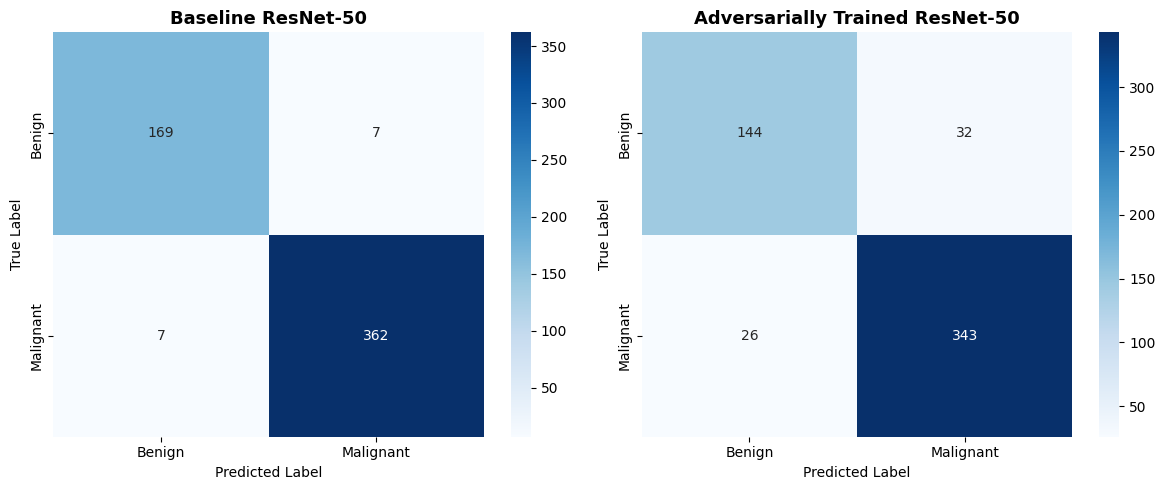

Confusion matrices saved.


In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels_names = ["Benign", "Malignant"]

for ax, cm, title in zip(axes,
                          [b_cm, r_cm],
                          ["Baseline ResNet-50", "Adversarially Trained ResNet-50"]):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels_names, yticklabels=labels_names, ax=ax)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "confusion_matrices.png"), dpi=150)
plt.show()
print("Confusion matrices saved.")

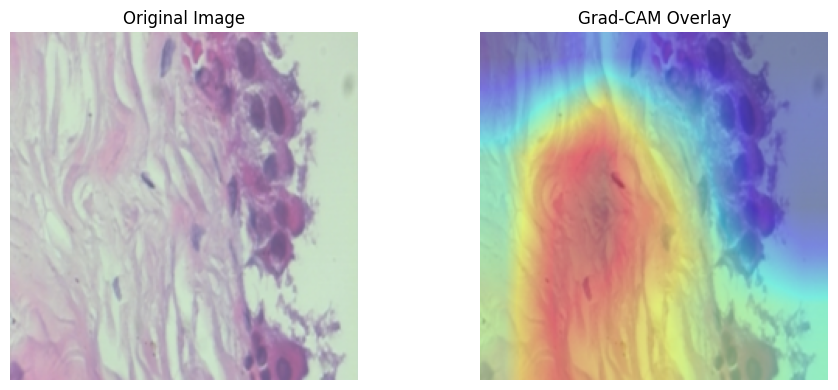

Grad-CAM saved.

✅ ALL DONE — Models saved to: /kaggle/working/breast_cancer_models


In [77]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


class GradCAM:
    def __init__(self, model, target_layer):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        self.model.zero_grad()
        output[0, class_idx].backward()
        weights     = self.gradients.mean(dim=[2, 3], keepdim=True)
        cam         = (weights * self.activations).sum(dim=1, keepdim=True)
        cam         = torch.relu(cam)
        cam         = cam.squeeze().cpu().numpy()
        cam         = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam


def overlay_gradcam(image_tensor, cam, alpha=0.4):
    """Overlay GradCAM heatmap on original image."""
    img = image_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    img = img * np.array(STD) + np.array(MEAN)
    img = np.clip(img, 0, 1)
    cam_resized = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    overlay = alpha * heatmap + (1 - alpha) * img
    return np.clip(overlay, 0, 1)


# Generate Grad-CAM for a sample test image
gradcam    = GradCAM(robust_model, robust_model.layer4[-1])
sample_img, sample_label = next(iter(test_loader))
sample_img   = sample_img[:1].to(DEVICE)
cam          = gradcam.generate(sample_img)
overlay      = overlay_gradcam(sample_img, cam)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
orig = sample_img.squeeze().permute(1,2,0).cpu().numpy()
orig = np.clip(orig * np.array(STD) + np.array(MEAN), 0, 1)
axes[0].imshow(orig);        axes[0].set_title("Original Image");   axes[0].axis('off')
axes[1].imshow(overlay);     axes[1].set_title("Grad-CAM Overlay"); axes[1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "gradcam_sample.png"), dpi=150)
plt.show()
print("Grad-CAM saved.")

print("\n✅ ALL DONE — Models saved to:", MODEL_DIR)


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/working/.virtual_documents/__notebook_source__.ipynb


In [ ]:
import shutil

shutil.make_archive(
    "/kaggle/working/models_backup",
    "zip",
    MODEL_DIR
)

In [1]:
from IPython.display import FileLink
FileLink('breast_cancer_models/robust_resnet50.pth')

/kaggle/working/breast_cancer_models/robust_resnet50.pth